<a href="https://colab.research.google.com/github/2303a510b9/Quantum-Computing-Hackathon/blob/main/problem_42.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Project Solution: R04 – Restricted Thermal Modelling
This notebook implements a classical Restricted Boltzmann Machine (RBM) to learn thermal and pattern probability distributions. We evaluate it using:
1. **D21:** 2×2 Bars and Stripes dataset.
2. **D22:** Four-qubit transverse-Ising thermal dataset generated via Exact Diagonalization.
```

In [1]:
# Install required libraries
!pip install -q qiskit qiskit-aer torch matplotlib seaborn

In [2]:
# Cell 1 - Import libraries
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import time
from scipy.spatial.distance import jensenshannon
from sklearn.model_selection import train_test_split

np.random.seed(42)
torch.manual_seed(42)
device = "cpu"

# Define all 16 states in binary format
all_states = np.array([[int(x) for x in f"{i:04b}"] for i in range(16)])
print("Libraries imported. All 16 binary states defined:")
print(all_states)

Libraries imported. All 16 binary states defined:
[[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]


In [3]:
# Cell 2 - Generate D21 Bars and Stripes dataset
def generate_bars_stripes(n_samples=5000):
    patterns = np.array([
        [0, 0, 0, 0],
        [1, 1, 0, 0],
        [0, 0, 1, 1],
        [1, 1, 1, 1],
        [0, 1, 0, 1],
        [1, 0, 1, 0]
    ])
    samples = patterns[np.random.choice(len(patterns), n_samples)]
    return samples, patterns

X_bas, bas_patterns = generate_bars_stripes()
print("Bars and Stripes Dataset Generated.")
print("Shape:", X_bas.shape)
print("Unique target patterns:", len(bas_patterns))

Bars and Stripes Dataset Generated.
Shape: (5000, 4)
Unique target patterns: 6


In [4]:
# Cell 3 - Generate D22 transverse-Ising thermal data
I = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Z = np.array([[1, 0], [0, -1]])
N = 4
J = 1.0
h = 0.8
beta = 1.2

def operator_on_qubit(op, position, n=4):
    operators = [op if i == position else I for i in range(n)]
    result = operators[0]
    for operator in operators[1:]:
        result = np.kron(result, operator)
    return result

# Construct full Transverse-Ising Hamiltonian
H = np.zeros((2**N, 2**N))
# ZZ nearest-neighbor interactions
for i in range(N - 1):
    Zi = operator_on_qubit(Z, i)
    Zj = operator_on_qubit(Z, i + 1)
    H -= J * (Zi @ Zj)

# X transverse-field term
for i in range(N):
    Xi = operator_on_qubit(X, i)
    H -= h * Xi

# Exact thermal state calculation
from scipy.linalg import expm
rho_unnormalized = expm(-beta * H)
Z_partition = np.trace(rho_unnormalized)
rho_thermal = rho_unnormalized / Z_partition

# Probability distribution in computational basis
target_probs = np.real(np.diag(rho_thermal))
target_probs = target_probs / np.sum(target_probs)

# Generate samples from target distribution
X_ising_indices = np.random.choice(16, size=5000, p=target_probs)
X_ising = all_states[X_ising_indices]

print("Transverse-Ising thermal probabilities generated:")
for idx, prob in enumerate(target_probs):
    print(f"State {idx:04b}: {prob:.4f}")

Transverse-Ising thermal probabilities generated:
State 0000: 0.2875
State 0001: 0.0574
State 0010: 0.0174
State 0011: 0.0457
State 0100: 0.0174
State 0101: 0.0051
State 0110: 0.0121
State 0111: 0.0574
State 1000: 0.0574
State 1001: 0.0121
State 1010: 0.0051
State 1011: 0.0174
State 1100: 0.0457
State 1101: 0.0174
State 1110: 0.0574
State 1111: 0.2875


In [5]:
# Cell 4 - Build Restricted Boltzmann Machine
class RestrictedBoltzmannMachine(torch.nn.Module):
    def __init__(self, visible=4, hidden=4):
        super().__init__()
        self.W = torch.nn.Parameter(0.01 * torch.randn(visible, hidden))
        self.visible_bias = torch.nn.Parameter(torch.zeros(visible))
        self.hidden_bias = torch.nn.Parameter(torch.zeros(hidden))
        self.visible = torch.tensor(all_states, dtype=torch.float32)

    def log_unnormalized(self):
        v = self.visible
        return (
            v @ self.visible_bias
            + F.softplus(v @ self.W + self.hidden_bias).sum(dim=1)
        )

    def probabilities(self):
        log_unnorm = self.log_unnormalized()
        return torch.softmax(log_unnorm, dim=0)

In [6]:
# Cell 5 - Train the model
def train_rbm(X, epochs=500, lr=0.03):
    start = time.perf_counter()
    X_train, X_test = train_test_split(X, test_size=0.25, random_state=42)
    rbm = RestrictedBoltzmannMachine(visible=4, hidden=4)
    optimizer = torch.optim.Adam(rbm.parameters(), lr=lr)

    # Empirical training distribution
    indices = (
        X_train[:, 0] * 8
        + X_train[:, 1] * 4
        + X_train[:, 2] * 2
        + X_train[:, 3]
    ).astype(int)
    counts = np.bincount(indices, minlength=16)
    data_probs = torch.tensor(counts / counts.sum(), dtype=torch.float32)

    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        model_probs = rbm.probabilities()
        # Kullback-Leibler loss
        loss = F.kl_div(torch.log(model_probs + 1e-10), data_probs, reduction='sum')
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    training_time = time.perf_counter() - start
    return rbm, X_test, losses, training_time

In [7]:
# Cell 6 - Evaluation metrics
def evaluate_rbm(rbm, X_test, target_distribution, name):
    start = time.perf_counter()
    with torch.no_grad():
        model_probs = rbm.probabilities().numpy()
    generation_time = time.perf_counter() - start

    # Total variation distance
    tv = 0.5 * np.sum(np.abs(target_distribution - model_probs))
    # Jensen-Shannon divergence
    js = jensenshannon(target_distribution, model_probs) ** 2

    # Generate samples
    generated_indices = np.random.choice(16, size=10000, p=model_probs)
    generated_samples = all_states[generated_indices]

    # Held-out NLL
    test_indices = (
        X_test[:, 0] * 8
        + X_test[:, 1] * 4
        + X_test[:, 2] * 2
        + X_test[:, 3]
    ).astype(int)
    nll = -np.mean(np.log(model_probs[test_indices] + 1e-10))

    # Target mode coverage
    active_modes = np.where(target_distribution > 0.01)[0]
    covered_modes = sum(1 for m in active_modes if model_probs[m] > 0.01)
    coverage = (covered_modes / len(active_modes)) * 100

    print(f"\nEvaluation Metrics for {name}:")
    print(f"Total Variation Distance: {tv:.5f}")
    print(f"Jensen-Shannon Divergence: {js:.5f}")
    print(f"Held-out Negative Log-Likelihood: {nll:.5f}")
    print(f"Target-mode Coverage: {coverage:.2f}%")

    return model_probs, generated_samples

In [8]:
# Cell 7 - Energy expectation error
H_zz = np.zeros((16, 16))
for i in range(N - 1):
    Zi = operator_on_qubit(Z, i)
    Zj = operator_on_qubit(Z, i + 1)
    H_zz -= J * (Zi @ Zj)
diagonal_energy = np.diag(H_zz)

def calculate_energy_error(target_distribution, model_distribution):
    target_energy = np.dot(target_distribution, diagonal_energy)
    model_energy = np.dot(model_distribution, diagonal_energy)
    error = abs(target_energy - model_energy)
    print(f"Target ZZ energy: {target_energy:.5f}")
    print(f"Generated ZZ energy: {model_energy:.5f}")
    print(f"Energy expectation error: {error:.5f}")
    return error

In [9]:
# Cell 8 - Run both experiments
print("\nBARS AND STRIPES EXPERIMENT")
rbm_bas, test_bas, losses_bas, time_bas = train_rbm(X_bas, epochs=500)

bas_target = np.zeros(16)
bas_indices = (
    bas_patterns[:, 0] * 8
    + bas_patterns[:, 1] * 4
    + bas_patterns[:, 2] * 2
    + bas_patterns[:, 3]
).astype(int)
bas_target[bas_indices] = 1.0 / len(bas_patterns)

probs_bas, samples_bas = evaluate_rbm(rbm_bas, test_bas, bas_target, "D21 - Bars and Stripes")

# Calculate effective energy diagnostic for Bars and Stripes
print("D21 Effective energy expectation error:")
bas_energy = -np.log(np.maximum(bas_target, 1e-10))
bas_error = abs(np.dot(bas_target, bas_energy) - np.dot(probs_bas, bas_energy))
print(f"Error: {bas_error:.5f}")

print("\nTRANSVERSE ISING EXPERIMENT")
rbm_ising, test_ising, losses_ising, time_ising = train_rbm(X_ising, epochs=500)
probs_ising, samples_ising = evaluate_rbm(rbm_ising, test_ising, target_probs, "D22 - Transverse Ising")
calculate_energy_error(target_probs, probs_ising)


BARS AND STRIPES EXPERIMENT

Evaluation Metrics for D21 - Bars and Stripes:
Total Variation Distance: 0.02469
Jensen-Shannon Divergence: 0.00467
Held-out Negative Log-Likelihood: 1.80583
Target-mode Coverage: 100.00%
D21 Effective energy expectation error:
Error: 0.27448

TRANSVERSE ISING EXPERIMENT

Evaluation Metrics for D22 - Transverse Ising:
Total Variation Distance: 0.02849
Jensen-Shannon Divergence: 0.00066
Held-out Negative Log-Likelihood: 2.06881
Target-mode Coverage: 100.00%
Target ZZ energy: -1.92173
Generated ZZ energy: -1.87079
Energy expectation error: 0.05094


np.float64(0.05094236919096651)

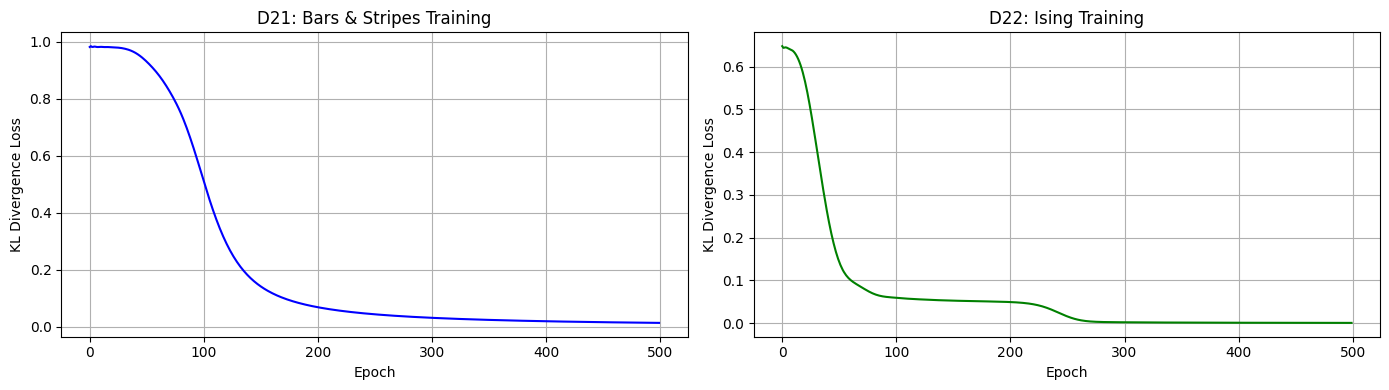

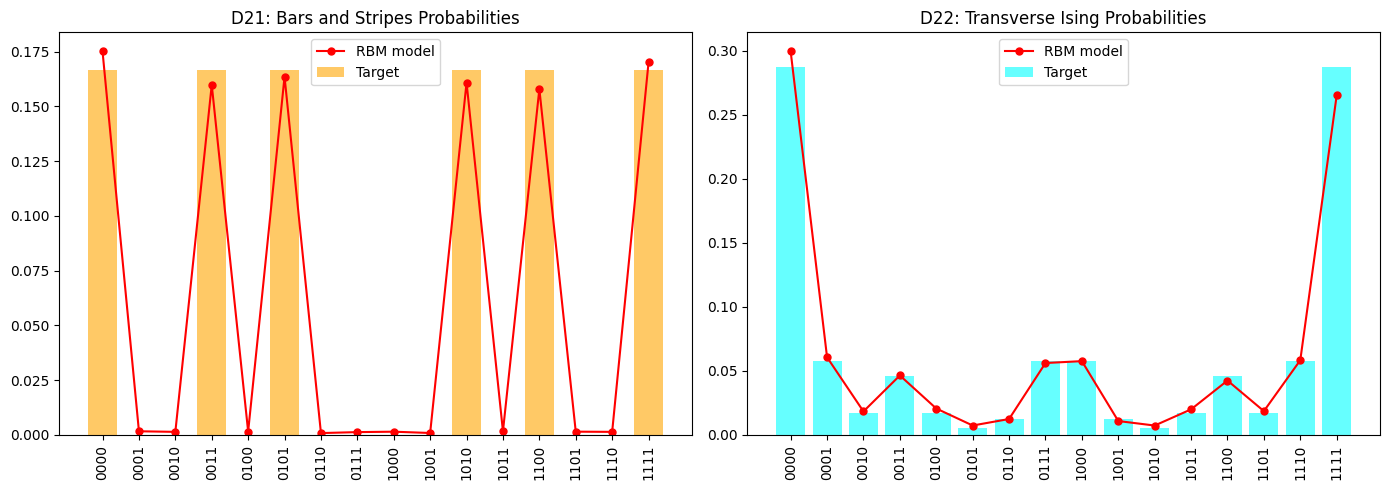

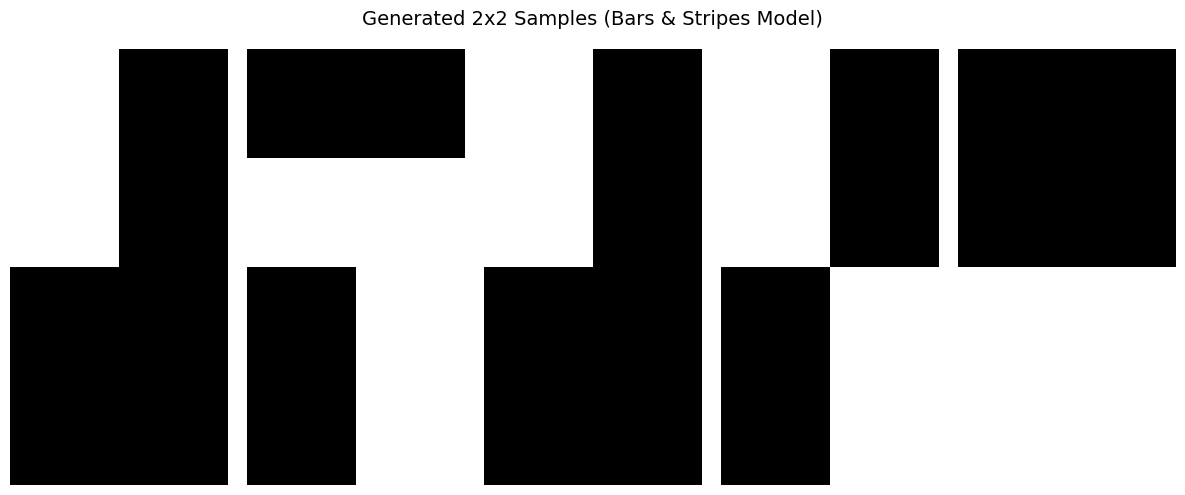

In [10]:
# Cell 9 - Visualize training and generated results
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(losses_bas, color='blue', label='Loss')
axes[0].set_title("D21: Bars & Stripes Training")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("KL Divergence Loss")
axes[0].grid(True)

axes[1].plot(losses_ising, color='green', label='Loss')
axes[1].set_title("D22: Ising Training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("KL Divergence Loss")
axes[1].grid(True)
plt.tight_layout()
plt.show()

# Probability distribution comparison
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.bar(range(16), bas_target, alpha=0.6, label="Target", color='orange')
plt.plot(probs_bas, "ro-", label="RBM model", markersize=5)
plt.title("D21: Bars and Stripes Probabilities")
plt.xticks(range(16), [f"{i:04b}" for i in range(16)], rotation=90)
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(range(16), target_probs, alpha=0.6, label="Target", color='cyan')
plt.plot(probs_ising, "ro-", label="RBM model", markersize=5)
plt.title("D22: Transverse Ising Probabilities")
plt.xticks(range(16), [f"{i:04b}" for i in range(16)], rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

# Display visual patterns generated
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
plt.suptitle("Generated 2x2 Samples (Bars & Stripes Model)", fontsize=14)
for i in range(10):
    ax = axes[i // 5, i % 5]
    pattern = samples_bas[np.random.choice(len(samples_bas))].reshape(2, 2)
    ax.imshow(pattern, cmap='binary', vmin=0, vmax=1)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [11]:
# Cell 10 - Quantum resource report
print("\nQUANTUM RESOURCE REPORT")
print("-" * 40)
print("Qubits simulated:", 4)
print("Visible units:", 4)
print("Hidden units:", 4)
print("Total parameters trained:", rbm_bas.W.numel() + rbm_bas.visible_bias.numel() + rbm_bas.hidden_bias.numel())
print("Sampling approximation: Exact classical diagonalization + Exact sampling")
print(f"D21 Training time: {time_bas:.4f} seconds")
print(f"D22 Training time: {time_ising:.4f} seconds")
print(f"D21 Generated samples during evaluation: {len(samples_bas)}")
print(f"D22 Generated samples during evaluation: {len(samples_ising)}")
print("\nEXPERIMENT COMPLETED SUCCESSFULLY")


QUANTUM RESOURCE REPORT
----------------------------------------
Qubits simulated: 4
Visible units: 4
Hidden units: 4
Total parameters trained: 24
Sampling approximation: Exact classical diagonalization + Exact sampling
D21 Training time: 13.7615 seconds
D22 Training time: 0.3801 seconds
D21 Generated samples during evaluation: 10000
D22 Generated samples during evaluation: 10000

EXPERIMENT COMPLETED SUCCESSFULLY
